
# CLT (Studentized) normalization of the digit frequencies of π

Companion to `pi_digit_surface.ipynb`. There, cross-sections were the raw frequencies $f_d(n)$, which level onto $0.1$.

Here no distributional model is assumed for the scale. For each digit $d$, let $X_k = \mathbf 1\{\text{$k$-th digit of π} = d\}$, so that $f_d(n) = \bar X_n$.
Each cross-section is then the one-sample $t$-statistic for the mean $0.1$,

$$z_d(n) = \sqrt{n}\,\frac{f_d(n) - 0.1}{s_d(n)}, \qquad s_d(n)^2 = \frac{1}{n-1}\sum_{k=1}^n \big(X_k - f_d(n)\big)^2 = \frac{n}{n-1}\,f_d(n)\big(1-f_d(n)\big),$$

where $s_d(n)$ is the sample standard deviation of those same $n$ indicators.

$s_d(n) = 0$ whenever digit $d$ has not yet appeared, so the surface starts at the first $n$ where all ten digits have occurred.
If the digit frequencies converge to $0.1$, then $s_d \to 0.3$ and this agrees asymptotically with the fixed-$\sigma$ scaling. What differs is the early part of the surface.
If the frequencies obey a CLT, each $z_d(n)$ is approximately $N(0,1)$, so the surface should **not** level. It should keep fluctuating at height $O(1)$.


In [1]:

import io, sys
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import Image as IPImage, display
from scipy import stats

sys.set_int_max_str_digits(0)
N = 100_000          # number of digits of π


## Digits of π (Machin's formula, exact integers)

In [2]:

def arctan_inv(x, unity):
    s = t = unity // x; x2 = x*x; k = 1; sign = -1
    while t:
        t //= x2; k += 2; s += sign * (t // k); sign = -sign
    return s

unity = 10**(N + 10)
pi = 4*(4*arctan_inv(5, unity) - arctan_inv(239, unity))
digits = np.frombuffer(str(pi)[:N].encode(), dtype=np.uint8) - 48   # 3, 1, 4, 1, 5, ...
assert "".join(map(str, digits[:12])) == "314159265358"


## Studentized cross-sections

In [3]:

onehot = np.zeros((N, 10)); onehot[np.arange(N), digits] = 1
n_all = np.arange(1, N+1)[:, None]
freq = np.cumsum(onehot, 0) / n_all
with np.errstate(divide="ignore", invalid="ignore"):
    sd = np.sqrt(freq * (1 - freq) * n_all / np.maximum(n_all - 1, 1))   # sample s.d., ddof = 1
    zall = np.sqrt(n_all) * (freq - 0.1) / sd                             # row n-1 = z(n)
zall[sd == 0] = np.nan

n0 = int(np.argmax(np.all(freq > 0, axis=1))) + 1      # first n with all ten digits present
print("all ten digits first present at n =", n0, " (the first 0 of π)")

ns = np.unique(np.round(np.logspace(np.log10(n0), np.log10(N), 160)).astype(int))
Z = zall[ns-1]
Y = np.log10(ns)
X = np.arange(10)
XX, YY = np.meshgrid(X, Y)
print("range of z for n >= n0:", np.nanmin(zall[n0-1:]).round(2), np.nanmax(zall[n0-1:]).round(2))


all ten digits first present at n = 33  (the first 0 of π)
range of z for n >= n0: -4.0 2.3


## Snapshot: $z_d(n)$ and $s_d(n)$ at a few $n$

In [4]:

print(f"{'n':>8}  " + " ".join(f"{d:>6}" for d in range(10)) + "   range of s_d")
for n in [n0, 100, 1000, 10_000, 100_000]:
    if n <= N:
        s = sd[n-1]
        print(f"{n:>8,}  " + " ".join(f"{v:>6.2f}" for v in zall[n-1]) + f"   {s.min():.3f}-{s.max():.3f}")


       n       0      1      2      3      4      5      6      7      8      9   range of s_d
      33   -2.30  -0.93   0.37   1.55  -0.18   0.37  -0.18  -0.93  -0.18   0.37   0.174-0.415
     100   -0.73  -0.73   0.61   0.61   0.00  -0.73  -0.35  -0.73   0.61   0.89   0.273-0.338
   1,000   -0.76   1.58   0.31   0.31  -0.76  -0.32  -0.65  -0.54   0.10   0.52   0.291-0.320
  10,000   -1.08   0.86   0.69  -0.84   0.40   1.50   0.69  -1.01  -1.81   0.46   0.293-0.306
 100,000   -0.01   1.44  -0.97   0.27  -0.31   0.27   0.29   0.26  -0.23  -1.04   0.299-0.302


## Render the animated PNG

In [5]:

ZLIM = 4
def render_frame(k, f, nframes):
    fig = plt.figure(figsize=(8, 6.4), dpi=90)
    ax = fig.add_subplot(projection="3d")
    ax.plot_surface(XX[:k], YY[:k], Z[:k], cmap="viridis", vmin=-3, vmax=3,
                    rstride=1, cstride=1, linewidth=0.15, edgecolor="k", antialiased=True)
    rx = [0, 9, 9, 0, 0]; ry = [Y[0], Y[0], Y[-1], Y[-1], Y[0]]
    for h, ls in [(0, "-"), (2, "--"), (-2, "--")]:           # outlines of z = 0 and ±2 planes
        ax.plot(rx, ry, [h]*5, color="crimson", lw=0.9, ls=ls)
    ax.set_xlim(0, 9); ax.set_ylim(Y[0], Y[-1]); ax.set_zlim(-ZLIM, ZLIM)
    ax.set_xticks(X); ax.set_xlabel("digit")
    ticks = list(range(int(np.ceil(Y[0])), int(Y[-1]) + 1))
    ax.set_yticks(ticks); ax.set_yticklabels([f"$10^{i}$" for i in ticks])
    ax.set_ylabel("n  (log scale)"); ax.set_zlabel(r"$z = \sqrt{n}\,(f-0.1)/s$")
    ax.view_init(elev=24, azim=-60 + 35 * f / nframes)
    n = ns[k-1]
    ax.set_title(f"Studentized digit frequencies in the first n digits of π\n"
                 f"n = {n:,}    max |z| = {np.nanmax(np.abs(Z[k-1])):.2f}", fontsize=11)
    buf = io.BytesIO(); fig.savefig(buf, format="png"); plt.close(fig)
    return Image.open(buf).convert("RGB")

nframes = 90
frames = [render_frame(max(2, round(len(ns) * f / nframes)), f, nframes)
          for f in range(1, nframes + 1)]
# one shared 256-colour palette for all frames (per-frame palettes get mangled in APNG)
pal = frames[-1].quantize(256)
frames = [fr.quantize(palette=pal, dither=Image.Dither.NONE) for fr in frames]
durations = [60]*(nframes - 1) + [2500]
frames[0].save("pi_digit_clt_surface.png", save_all=True, append_images=frames[1:],
               duration=durations, loop=0, optimize=True)


## Display

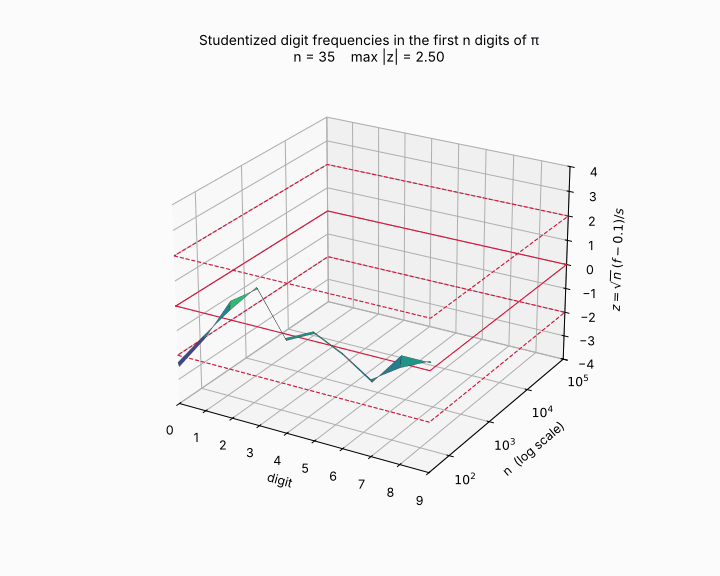

In [6]:
display(IPImage(filename="pi_digit_clt_surface.png"))


## Diagnostics

**Left:** the ten paths $n \mapsto z_d(n)$ against $\pm 1.96$. These are random-walk-like and wander on the $\log n$ scale rather than converging.
**Right:** at a fixed $n$ there are only ten values, which is too few for a histogram. Instead this pools $z_d(n)$ at $n = 10^3, 2\cdot10^3, \dots$ and compares them with $N(0,1)$. The pooled values are correlated across $n$, so the fit is indicative only.


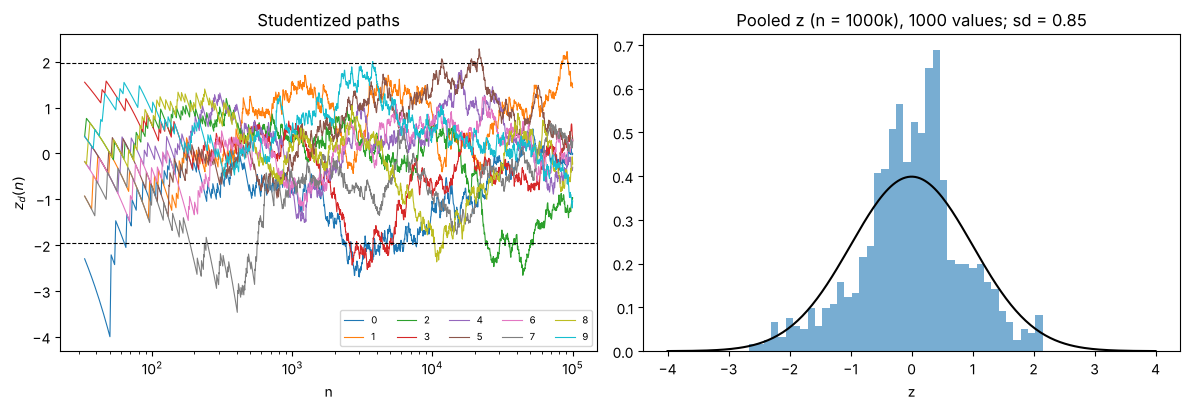

In [7]:

fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
idx = np.unique(np.round(np.logspace(np.log10(n0), np.log10(N), 2000)).astype(int)) - 1
for d in range(10):
    axs[0].plot(idx + 1, zall[idx, d], lw=0.8, label=str(d))
for h in (1.96, -1.96): axs[0].axhline(h, color="k", ls="--", lw=0.8)
axs[0].set_xscale("log"); axs[0].set_xlabel("n"); axs[0].set_ylabel("$z_d(n)$")
axs[0].set_title("Studentized paths"); axs[0].legend(ncol=5, fontsize=7, loc="lower right")

pool = zall[np.arange(1000, N + 1, 1000) - 1].ravel()
t = np.linspace(-4, 4, 200)
axs[1].hist(pool, bins=40, density=True, alpha=0.6)
axs[1].plot(t, stats.norm.pdf(t), "k")
axs[1].set_title(f"Pooled z (n = 1000k), {pool.size} values; sd = {pool.std():.2f}")
axs[1].set_xlabel("z")
plt.tight_layout(); plt.show()
